<a href="https://colab.research.google.com/github/LIKHITA12/Face_Mask_Detection_Alexnet_Architecture/blob/main/Face_Mask_Detection_Alexnet_Architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Face Mask Detection using AlexNet**

### SETTING UP THE ENVIRONMENT AND IMPORTING PACKAGES

In [ ]:
# check for GPU availability.
!nvidia-smi

# Mount Google Drive to access the dataset.
from google.colab import drive
drive.mount('/content/drive')

# Import necessary libraries
import os
import numpy as np
import random
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam # Import the Adam optimizer
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from PIL import Image
import glob
import shutil
import warnings

# Ignore unnecessary warnings for a cleaner output.
warnings.filterwarnings('ignore')


### DATA PREPROCESSING

In [ ]:
# Define the path to the dataset and the class labels.
data_zip_path = '/content/drive/MyDrive/Face_mask_dataset.zip'
unzip_destination = '/content/Face_mask_dataset/'
classes = {0: 'No Mask', 1: 'Mask'}

# Unzip the dataset from Google Drive.
# The '-q' flag makes the output quiet.
!unzip -q "{data_zip_path}" -d "/content/"

print("✅ Dataset unzipped successfully.")

### EXPLORATORY DATA ANALYSIS (EDA)

In [ ]:
print("\n--- Exploratory Data Analysis ---")
mask_dir = os.path.join(unzip_destination, 'Mask')
no_mask_dir = os.path.join(unzip_destination, 'No Mask')

mask_images = os.listdir(mask_dir)
no_mask_images = os.listdir(no_mask_dir)

# --- 1. Class Distribution ---
num_mask = len(mask_images)
num_no_mask = len(no_mask_images)
total_images = num_mask + num_no_mask

print(f"Total images with mask: {num_mask}")
print(f"Total images without mask: {num_no_mask}")
print(f"Total images: {total_images}")

# Bar chart for class distribution
plt.figure(figsize=(6, 4))
plt.bar(['With Mask', 'Without Mask'], [num_mask, num_no_mask], color=['green', 'red'])
plt.title('Class Distribution')
plt.ylabel('Number of Images')
plt.show()

# --- 2. Display Sample Images ---
def show_sample_images(image_paths, title, n=4):
    plt.figure(figsize=(10, 3))
    for i in range(n):
        plt.subplot(1, n, i+1)
        img_path = os.path.join(image_paths, random.choice(os.listdir(image_paths)))
        img = Image.open(img_path)
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.show()

print("\nSample 'With Mask' Images:")
show_sample_images(mask_dir, 'With Mask')

print("\nSample 'Without Mask' Images:")
show_sample_images(no_mask_dir, 'Without Mask')

### DATA AUGMENTATION AND GENERATORS

In [ ]:
# Using ImageDataGenerator for data augmentation and creating train/validation sets.
# Data Augmentation configuration for the training set.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    rotation_range=20,
    horizontal_flip=True,
    validation_split=0.2  # Reserve 20% of the data for validation.
)

# We create two generators from the same directory using the validation_split.
print("Creating Training Data Generator...")
training_set = train_datagen.flow_from_directory(
    unzip_destination,
    target_size=(100, 100),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

print("\nCreating Validation Data Generator...")
validation_set = train_datagen.flow_from_directory(
    unzip_destination,
    target_size=(100, 100),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=False # Important: Set shuffle to False for evaluation
)

### VISUALIZE DATA AUGMENTATION

In [ ]:
print("\n--- Visualizing Data Augmentation ---")
# Get a single image from the training set to demonstrate augmentation
sample_img_path = os.path.join(mask_dir, random.choice(mask_images))
sample_img = Image.open(sample_img_path)
sample_img_array = np.array(sample_img.resize((100, 100)))
sample_img_array = np.expand_dims(sample_img_array, axis=0) # Add batch dimension

# Create an iterator to generate augmented images
aug_iter = train_datagen.flow(sample_img_array, batch_size=1)

# Plot the original image and 8 augmented versions
plt.figure(figsize=(12, 6))
plt.subplot(3, 3, 1)
plt.imshow(sample_img)
plt.title('Original Image')
plt.axis('off')

for i in range(8):
    plt.subplot(3, 3, i+2)
    augmented_batch = next(aug_iter)
    augmented_image = augmented_batch[0] # The image is the first element in the batch
    plt.imshow(augmented_image)
    plt.title(f'Augmented {i+1}')
    plt.axis('off')
plt.suptitle('Demonstration of Data Augmentation', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


### BUILDING THE ALEXNET MODEL

In [ ]:
# Defining the AlexNet-style Convolutional Neural Network (CNN).
AlexNet_model = Sequential([
    # 1st Convolutional Layer
    Conv2D(filters=96, kernel_size=(11,11), strides=(4,4), activation='relu', input_shape=(100,100,3)),
    MaxPooling2D(pool_size=(3,3), strides=(2,2)),

    # 2nd Convolutional Layer
    Conv2D(filters=256, kernel_size=(5,5), strides=(1,1), activation='relu', padding="same"),
    MaxPooling2D(pool_size=(3,3), strides=(2,2)),

    # 3rd-5th Convolutional Layers
    Conv2D(filters=384, kernel_size=(3,3), strides=(1,1), activation='relu', padding="same"),
    Conv2D(filters=384, kernel_size=(3,3), strides=(1,1), activation='relu', padding="same"),
    Conv2D(filters=256, kernel_size=(3,3), strides=(1,1), activation='relu', padding="same"),
    MaxPooling2D(pool_size=(3,3), strides=(2,2)),

    # Flattening Layer
    Flatten(),

    # Fully Connected Layers
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(4096, activation='relu'),
    Dropout(0.5),

    # Output Layer
    Dense(1, activation='sigmoid')
])

# A smaller learning rate like 0.0001 allows for more stable training.
optimizer = Adam(learning_rate=0.0001)

# Compile the model with the new optimizer
AlexNet_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Print model summary
AlexNet_model.summary()

### TRAINING THE MODEL

In [ ]:
# Train the model using the .fit() method with our data generators.
history = AlexNet_model.fit(
    training_set,
    validation_data=validation_set,
    epochs=20 # Let's stick with 20 epochs for now
)

print("\n✅ Model training complete.")


### VISUALIZING TRAINING RESULTS

In [ ]:
# Plotting the training and validation accuracy and loss to check for overfitting.
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### COMPREHENSIVE MODEL EVALUATION

In [ ]:
print("\n--- Comprehensive Model Evaluation ---")
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Make predictions on the entire validation set
validation_set.reset()
Y_pred = AlexNet_model.predict(validation_set, steps=validation_set.samples // validation_set.batch_size + 1)
# Convert probabilities to binary class labels
y_pred = (Y_pred > 0.5).astype("int32")

# Get the true labels
y_true = validation_set.classes

# --- 1. Classification Report ---
print("\nClassification Report:")
class_labels = list(validation_set.class_indices.keys())
print(classification_report(y_true, y_pred, target_names=class_labels))


# --- 2. Confusion Matrix ---
print("\nConfusion Matrix:")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()


### PREDICTING ON A NEW IMAGE

Tue Jun 10 15:07:30 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

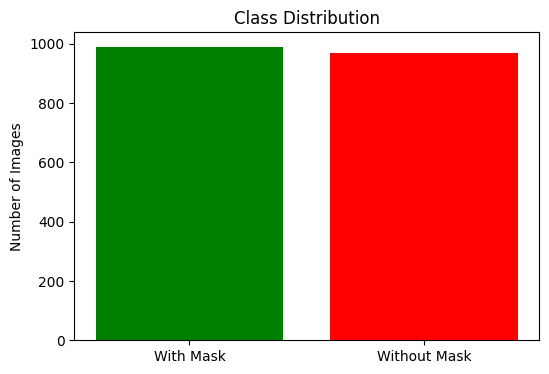


Sample 'With Mask' Images:


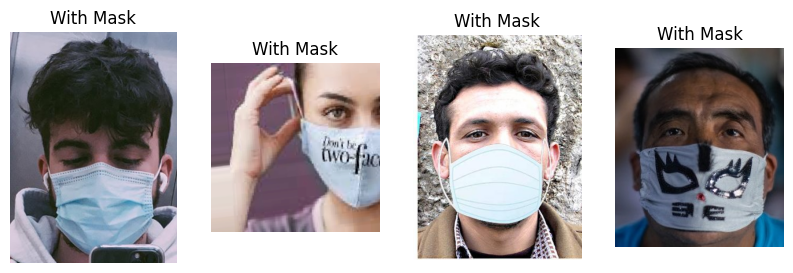


Sample 'Without Mask' Images:


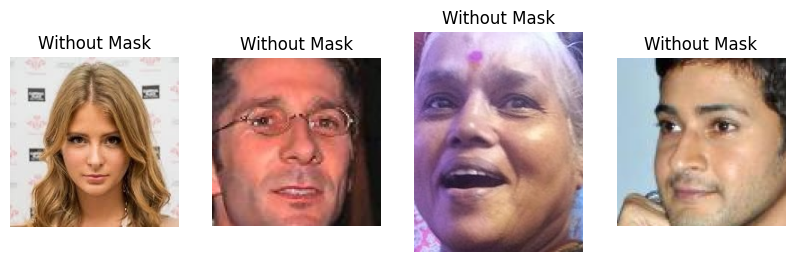

Creating Training Data Generator...
Found 1567 images belonging to 2 classes.

Creating Validation Data Generator...
Found 390 images belonging to 2 classes.

--- Visualizing Data Augmentation ---


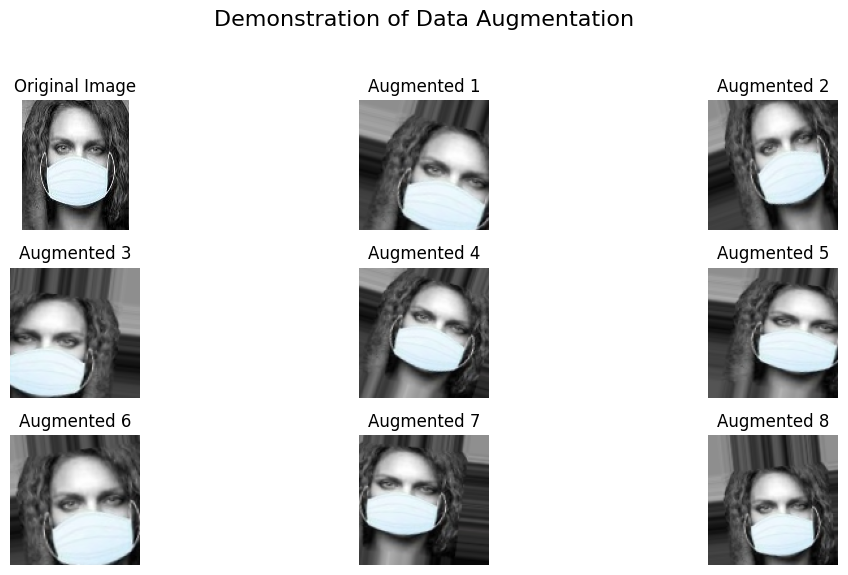

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 23, 23, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 5, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 5, 5, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 5, 5, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     4,198,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,731,009 (94.34 MB)

 Trainable params: 24,731,009 (94.34 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 314ms/step - accuracy: 0.5917 - loss: 0.6534 - val_accuracy: 0.8308 - val_loss: 0.4325
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 11s 198ms/step - accuracy: 0.8735 - loss: 0.3369 - val_accuracy: 0.8077 - val_loss: 0.4538
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 10s 193ms/step - accuracy: 0.9079 - loss: 0.2691 - val_accuracy: 0.8821 - val_loss: 0.3310
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 164ms/step - accuracy: 0.8604 - loss: 0.3086 - val_accuracy: 0.9128 - val_loss: 0.2515
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 188ms/step - accuracy: 0.9396 - loss: 0.1916 - val_accuracy: 0.8846 - val_loss: 0.2868
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 186ms/step - accuracy: 0.9263 - loss: 0.1762 - val_accuracy: 0.9179 - val_loss: 0.2210
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 164ms/step - accuracy: 0.9323 - loss: 0.1847 - val_accuracy: 0.9333 - val_loss: 0.1875
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 193ms/step - accuracy: 0.9468 - loss: 0.1478 - val_accuracy:

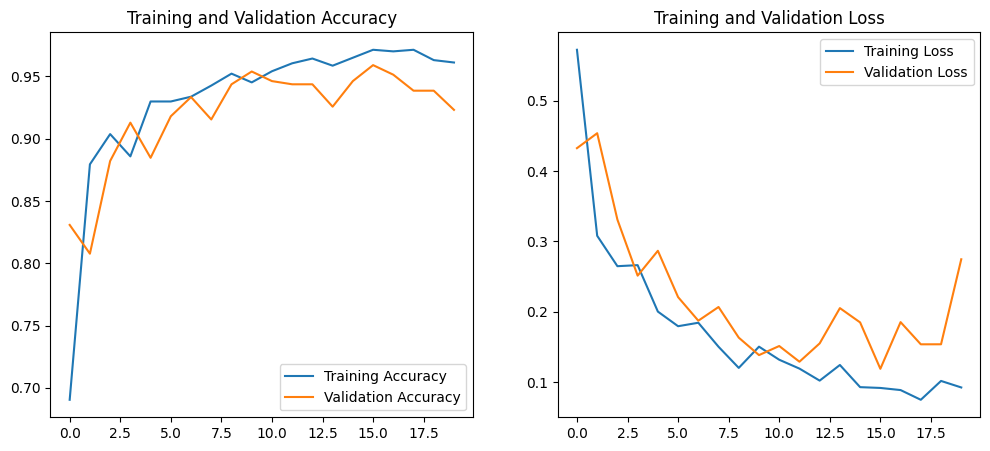


--- Comprehensive Model Evaluation ---
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step

Classification Report:
              precision    recall  f1-score   support

        Mask       0.99      0.84      0.91       197
     No Mask       0.86      0.99      0.92       193

    accuracy                           0.92       390
   macro avg       0.93      0.92      0.92       390
weighted avg       0.93      0.92      0.92       390


Confusion Matrix:


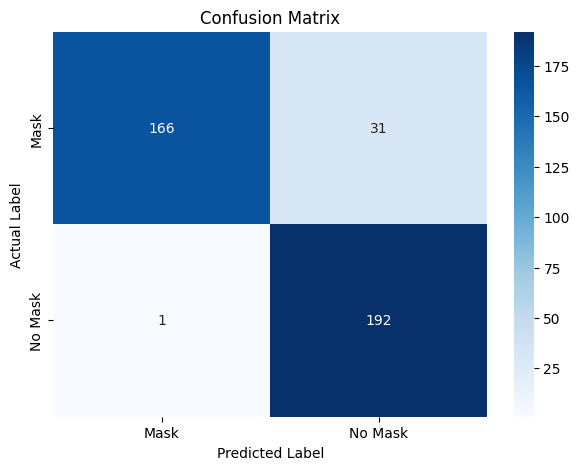

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 834ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step

--- Prediction on a 'No Mask' Image ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


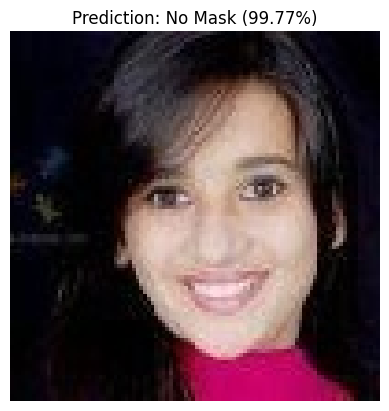


--- Prediction on a 'Mask' Image ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


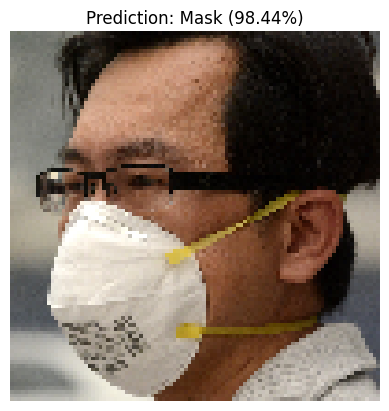

In [ ]:
from tensorflow.keras.preprocessing import image

# Let's test with an image from our validation set.
val_image_paths = validation_set.filepaths

# Find the index of the first image with label 0 (No Mask)
idx_no_mask = np.where(y_true == 0)[0][0]
no_mask_path = val_image_paths[idx_no_mask]
img_no_mask = image.load_img(no_mask_path, target_size=(100, 100))
img_no_mask_array = image.img_to_array(img_no_mask)
img_no_mask_batch = np.expand_dims(img_no_mask_array, axis=0) / 255.0

prediction_no_mask = AlexNet_model.predict(img_no_mask_batch)

# Find the index of the first image with label 1 (Mask)
idx_mask = np.where(y_true == 1)[0][0]
mask_path = val_image_paths[idx_mask]
img_mask = image.load_img(mask_path, target_size=(100, 100))
img_mask_array = image.img_to_array(img_mask)
img_mask_batch = np.expand_dims(img_mask_array, axis=0) / 255.0

prediction_mask = AlexNet_model.predict(img_mask_batch)

# Get the class indices from the generator: e.g., {'Mask': 0, 'No Mask': 1}
class_indices = training_set.class_indices
# Invert the dictionary to map from index to name: e.g., {0: 'Mask', 1: 'No Mask'}
labels_map = {v: k for k, v in class_indices.items()}

# --- Display results ---
def display_prediction(img, prediction):
    plt.imshow(img)
    plt.axis('off')
    raw_pred_value = prediction[0][0]

    # Determine the predicted label and confidence score.
    if raw_pred_value < 0.5:
        # The model is predicting class '0'.
        predicted_class_index = 0
        confidence = (1 - raw_pred_value) * 100
    else:
        # The model is predicting class '1'.
        predicted_class_index = 1
        confidence = raw_pred_value * 100

    # Look up the class name from our dynamically created map
    pred_label = labels_map[predicted_class_index]

    plt.title(f"Prediction: {pred_label} ({confidence:.2f}%)")
    plt.show()

print("\n--- Prediction on a 'No Mask' Image ---")

try:
    no_mask_class_index = [k for k, v in labels_map.items() if v == 'No Mask'][0]
    idx_no_mask = np.where(y_true == no_mask_class_index)[0][0]
    no_mask_path = val_image_paths[idx_no_mask]
    img_no_mask = image.load_img(no_mask_path, target_size=(100, 100))
    img_no_mask_array = image.img_to_array(img_no_mask)
    img_no_mask_batch = np.expand_dims(img_no_mask_array, axis=0) / 255.0
    prediction_no_mask = AlexNet_model.predict(img_no_mask_batch)
    display_prediction(img_no_mask, prediction_no_mask)
except IndexError:
    print("Could not find a 'No Mask' image in the first batch of the validation set.")


print("\n--- Prediction on a 'Mask' Image ---")

try:
    mask_class_index = [k for k, v in labels_map.items() if v == 'Mask'][0]
    idx_mask = np.where(y_true == mask_class_index)[0][0]
    mask_path = val_image_paths[idx_mask]
    img_mask = image.load_img(mask_path, target_size=(100, 100))
    img_mask_array = image.img_to_array(img_mask)
    img_mask_batch = np.expand_dims(img_mask_array, axis=0) / 255.0
    prediction_mask = AlexNet_model.predict(img_mask_batch)
    display_prediction(img_mask, prediction_mask)
except IndexError:
    print("Could not find a 'Mask' image in the first batch of the validation set.")

